# Exploration: `gobuster.csv`


In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"  # tqdm-Fortschrittsbalken aus fit() würden das Notebook aufblähen

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from flowextractor.model.model import (
    AttackDetectionNet, normalize_training_data, print_metrics, FEATURE_COLUMNS, LOG_SCALED_COLUMNS,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = "gobuster"  # "ssh_bruteforce" | "gobuster" | "slowloris"
DATASETS = {
    "ssh_bruteforce": {"csv": "ssh_bruteforce.csv", "port": 22, "service": "SSH"},
    "gobuster": {"csv": "gobuster.csv", "port": 443, "service": "HTTPS"},
    "slowloris": {"csv": "slowloris.csv", "port": 443, "service": "HTTPS"},
}
CSV_PATH = ROOT / DATASETS[DATASET]["csv"]
SVC_PORT = DATASETS[DATASET]["port"]   # Port des angegriffenen Dienstes
SVC = DATASETS[DATASET]["service"]

SEED = 42
EPOCHS = 20        # wie der CLI-Default von flowmodel
BATCH_SIZE = 32    # wie der CLI-Default von flowmodel
CUTOFF = 0.5

# Das Netz ist winzig: auf der CPU ist ein Thread ~8x schneller als Multi-Threading (Sync-Overhead)
torch.set_num_threads(1)

# Farben: Klasse = Identität -> feste kategoriale Slots
C_BENIGN, C_MAL, C_ALT = "#2a78d6", "#eb6834", "#1baf7a"
CLASS_COLORS = {"benign": C_BENIGN, "malicious": C_MAL}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

W20261019 09:08:32.333808 140013744303872 agent.cpp:608] sysfs nodes path '/sys/class/kfd/kfd/topology/nodes' does not exist


## 1. Überblick & Datenqualität

In [2]:
raw = pd.read_csv(CSV_PATH)
raw["is_mal"] = (raw["Label"] == "malicious").astype(int)
raw["is_svc"] = (raw["Source Port"] == SVC_PORT) | (raw["Destination Port"] == SVC_PORT)
print(f"Datei: {CSV_PATH.name} ({CSV_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Flows: {len(raw):,}  |  Spalten: {raw.shape[1] - 2}")
raw.head()

Datei: gobuster.csv (38.3 MB)
Flows: 295,804  |  Spalten: 15


,Flow Hash,Source IP,Destination IP,Number of Packets,Source Port,Destination Port,Average Packet Size,Minimum Packet Size,Maximum Packet Size,Total Bytes,IAT Min,IAT Max,IAT Mean,Label,Attack Type,is_mal,is_svc
0,7567630335590970478,85.217.140.49,37.60.229.253,1,42101,28811,66.0000,66,66,66,inf,0.0000,0.0000,benign,NaN,0,False
1,7230612664221465358,37.60.229.253,85.217.140.49,1,28811,42101,54.0000,54,54,54,inf,0.0000,0.0000,benign,NaN,0,False
2,-3075897080288914886,135.181.138.95,37.60.229.253,1,50510,30656,74.0000,74,74,74,inf,0.0000,0.0000,benign,NaN,0,False
3,4612642979632836404,37.60.229.253,135.181.138.95,1,30656,50510,54.0000,54,54,54,inf,0.0000,0.0000,benign,NaN,0,False
4,1558164855522324884,141.89.234.2,37.60.229.253,219,34814,22,97.8904,66,102,21438,0.0000,2.0141,0.0884,benign,NaN,0,False


In [3]:
num_cols = raw.select_dtypes("number").columns.drop(["is_mal", "Flow Hash"])
quality = pd.DataFrame({
    "dtype": raw[num_cols].dtypes.astype(str),
    "NaN": raw[num_cols].isna().sum(),
    "inf": np.isinf(raw[num_cols]).sum(),
    "Null-Werte": (raw[num_cols] == 0).sum(),
    "unique": raw[num_cols].nunique(),
})
quality

,dtype,NaN,inf,Null-Werte,unique
Number of Packets,int64,0,0,0,535
Source Port,int64,0,0,0,63553
Destination Port,int64,0,0,0,63584
Average Packet Size,float64,0,0,0,47301
Minimum Packet Size,int64,0,0,0,279
Maximum Packet Size,int64,0,0,0,992
Total Bytes,int64,0,0,0,26553
IAT Min,float64,0,151663,41940,16765
IAT Max,float64,0,0,151679,140650
IAT Mean,float64,0,0,151679,143726


In [4]:
print("Label-Werte:", raw["Label"].value_counts(dropna=False).to_dict())
print("Attack Type:", raw["Attack Type"].value_counts(dropna=False).to_dict())
single = raw["Number of Packets"] == 1
print(f"\nFlows mit genau 1 Paket: {single.sum():,} ({single.mean():.1%})  -> IAT Min = inf bei {np.isinf(raw['IAT Min']).sum():,} Flows")
print(f"inf in 'IAT Min' nur bei 1-Paket-Flows: {np.isinf(raw.loc[~single, 'IAT Min']).sum() == 0}")

dup = raw["Flow Hash"].duplicated(keep=False)
conflict = raw[dup].groupby("Flow Hash")["Label"].nunique().gt(1).sum()
print(f"\nFlow-Hashes mehrfach vorhanden: {raw['Flow Hash'].duplicated().sum():,} Duplikate "
      f"({dup.sum():,} betroffene Zeilen), davon Hashes mit widersprüchlichem Label: {conflict}")
print(f"Komplett identische Feature-Zeilen (ohne Hash): {raw.drop(columns=['Flow Hash']).duplicated().sum():,}")

Label-Werte: {'benign': 217182, 'malicious': 78622}


Attack Type: {nan: 217182, 'gobuster_scan': 78622}

Flows mit genau 1 Paket: 151,663 (51.3%)  -> IAT Min = inf bei 151,663 Flows
inf in 'IAT Min' nur bei 1-Paket-Flows: True

Flow-Hashes mehrfach vorhanden: 23,708 Duplikate (41,876 betroffene Zeilen), davon Hashes mit widersprüchlichem Label: 0


Komplett identische Feature-Zeilen (ohne Hash): 1,041


## 2. Klassenverteilung & zeitlicher Verlauf

,Flows,Anteil
Label,,
benign,217182,73.42%
malicious,78622,26.58%


Imbalance-Verhältnis benign : malicious = 2.8 : 1


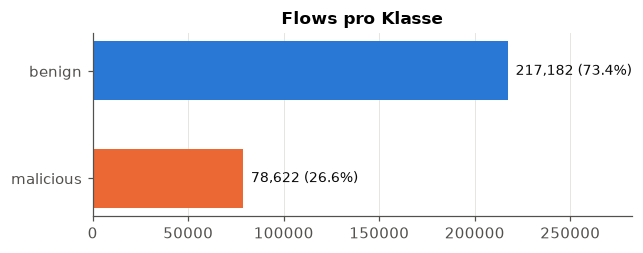

In [5]:
counts = raw["Label"].value_counts()
share = raw["Label"].value_counts(normalize=True)
display(pd.DataFrame({"Flows": counts, "Anteil": share.map("{:.2%}".format)}))
print(f"Imbalance-Verhältnis benign : malicious = {counts['benign'] / counts['malicious']:.1f} : 1")

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index], height=0.55)
for i, (c, v) in enumerate(counts.items()):
    ax.text(v, i, f"  {v:,} ({share[c]:.1%})", va="center", color=INK, fontsize=9)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_title("Flows pro Klasse")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

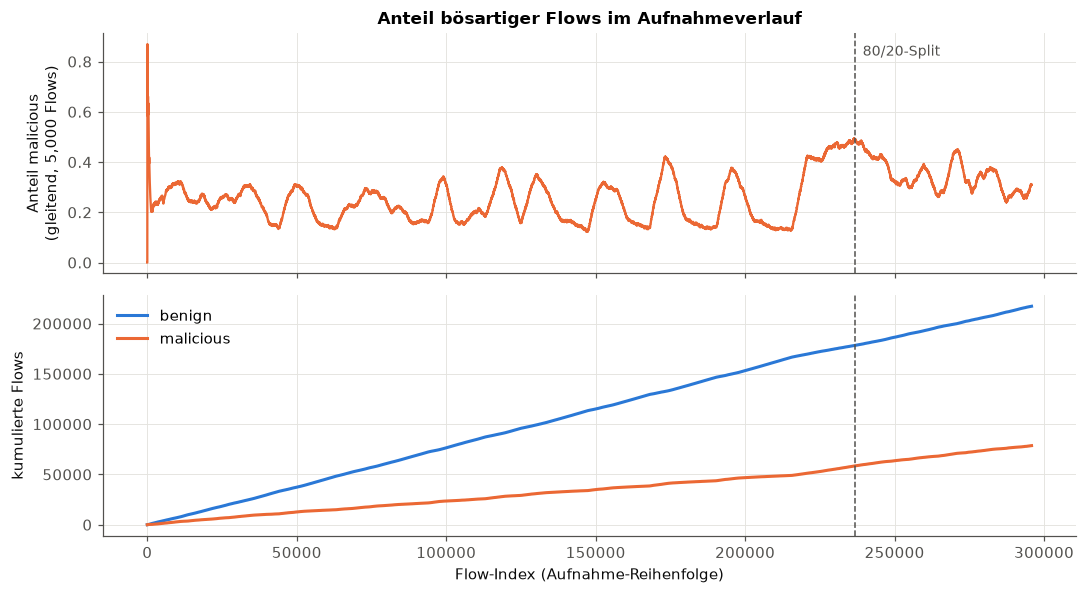

,Flows,malicious,Anteil malicious
Train (erste 80 %),236643,58426,0.2469
Test (letzte 20 %),59161,20196,0.3414


In [6]:
split_idx = int(len(raw) * 0.8)
window = 5000
rolling = raw["is_mal"].rolling(window, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(rolling.index, rolling.values, color=C_MAL, linewidth=1.5)
axes[0].set_ylabel(f"Anteil malicious\n(gleitend, {window:,} Flows)")
axes[0].set_title("Anteil bösartiger Flows im Aufnahmeverlauf")
axes[1].plot(raw.index, (1 - raw["is_mal"]).cumsum(), color=C_BENIGN, label="benign")
axes[1].plot(raw.index, raw["is_mal"].cumsum(), color=C_MAL, label="malicious")
axes[1].set_ylabel("kumulierte Flows")
axes[1].set_xlabel("Flow-Index (Aufnahme-Reihenfolge)")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.axvline(split_idx, color=INK_MUTED, linestyle="--", linewidth=1)
axes[0].text(split_idx, axes[0].get_ylim()[1] * 0.95, "  80/20-Split", color=INK_MUTED, va="top", fontsize=9)
plt.tight_layout()
plt.show()

split_stats = pd.DataFrame({
    "Flows": [split_idx, len(raw) - split_idx],
    "malicious": [raw["is_mal"][:split_idx].sum(), raw["is_mal"][split_idx:].sum()],
}, index=["Train (erste 80 %)", "Test (letzte 20 %)"])
split_stats["Anteil malicious"] = split_stats["malicious"] / split_stats["Flows"]
split_stats

## 3. Feature-Verteilungen

In [7]:
feature_stats = raw.groupby("Label")[FEATURE_COLUMNS].median().T
feature_stats.columns = [f"Median {c}" for c in feature_stats.columns]
mean_stats = raw.replace(np.inf, np.nan).groupby("Label")[FEATURE_COLUMNS].mean().T
feature_stats["Mean benign"] = mean_stats["benign"]
feature_stats["Mean malicious"] = mean_stats["malicious"]
feature_stats

,Median benign,Median malicious,Mean benign,Mean malicious
Number of Packets,1.0000,436.0000,5.2218,318.3084
Source Port,"37,865.0000",734.5000,"32,110.7430","16,889.8240"
Destination Port,"37,775.0000",734.5000,"32,005.0087","16,889.8240"
Average Packet Size,66.0000,186.0690,124.5172,258.3726
Minimum Packet Size,66.0000,66.0000,65.0275,63.7117
Maximum Packet Size,66.0000,369.0000,412.3815,"1,565.8203"
Total Bytes,66.0000,"79,348.5000","2,031.9587","59,170.2129"
IAT Min,inf,0.0000,0.5042,0.0137
IAT Max,0.0000,0.8640,1.2159,5.0002
IAT Mean,0.0000,0.0432,0.3650,0.7950


In [8]:
raw.replace(np.inf, np.nan).groupby("Label")[LOG_SCALED_COLUMNS].describe().T.unstack(level=1)

Label                     benign                                                                            malicious                                  \
                           count       mean          std     min     25%     50%      75%             max       count        mean         std     min   
Number of Packets   217,182.0000     5.2218     139.3414  1.0000  1.0000  1.0000   5.0000     52,886.0000 78,622.0000    318.3084    207.4601  1.0000   
Average Packet Size 217,182.0000   124.5172     161.9256 54.0000 54.0000 66.0000 110.9358     11,504.6727 78,622.0000    258.3726    224.3439 62.0000   
Minimum Packet Size 217,182.0000    65.0275      33.4983 54.0000 54.0000 66.0000  66.0000      1,506.0000 78,622.0000     63.7117      3.1872 60.0000   
Maximum Packet Size 217,182.0000   412.3815     782.0539 54.0000 54.0000 66.0000 150.0000     65,226.0000 78,622.0000  1,565.8203  1,252.4290 66.0000   
Total Bytes         217,182.0000 2,031.9587 190,242.0686 54.0000 54.0000 66.0000 448.0000 69,888,651.0000 78,622.0000 59,170.2129 37,800.8455 66.0000   
IAT Min              65,564.0000     0.5042       4.1972  0.0000  0.0000  0.0000   0.0002         84.8098 78,577.0000      0.0137      0.4548  0.0000   
IAT Max             217,182.0000     1.2159       5.4667  0.0000  0.0000  0.0000   0.0357         90.7784 78,622.0000      5.0002      6.7400  0.0000   
IAT Mean            217,182.0000     0.3650       2.6697  0.0000  0.0000  0.0000   0.0108         84.8098 78,622.0000      0.7950      1.3054  0.0000   

Label                                                                
                           25%         50%         75%          max  
Number of Packets      10.0000    436.0000    459.0000   1,040.0000  
Average Packet Size   172.4584    186.0690    188.0209   1,771.0000  
Minimum Packet Size    60.0000     66.0000     66.0000     183.0000  
Maximum Packet Size   369.0000    369.0000  2,862.0000   2,862.0000  
Total Bytes         5,675.0000 79,348.5000 83,239.0000 203,473.0000  
IAT Min                 0.0000      0.0000      0.0000      15.5526  
IAT Max                 0.5579      0.8640     15.0295      30.7084  
IAT Mean                0.0382      0.0432      1.9047      15.5526

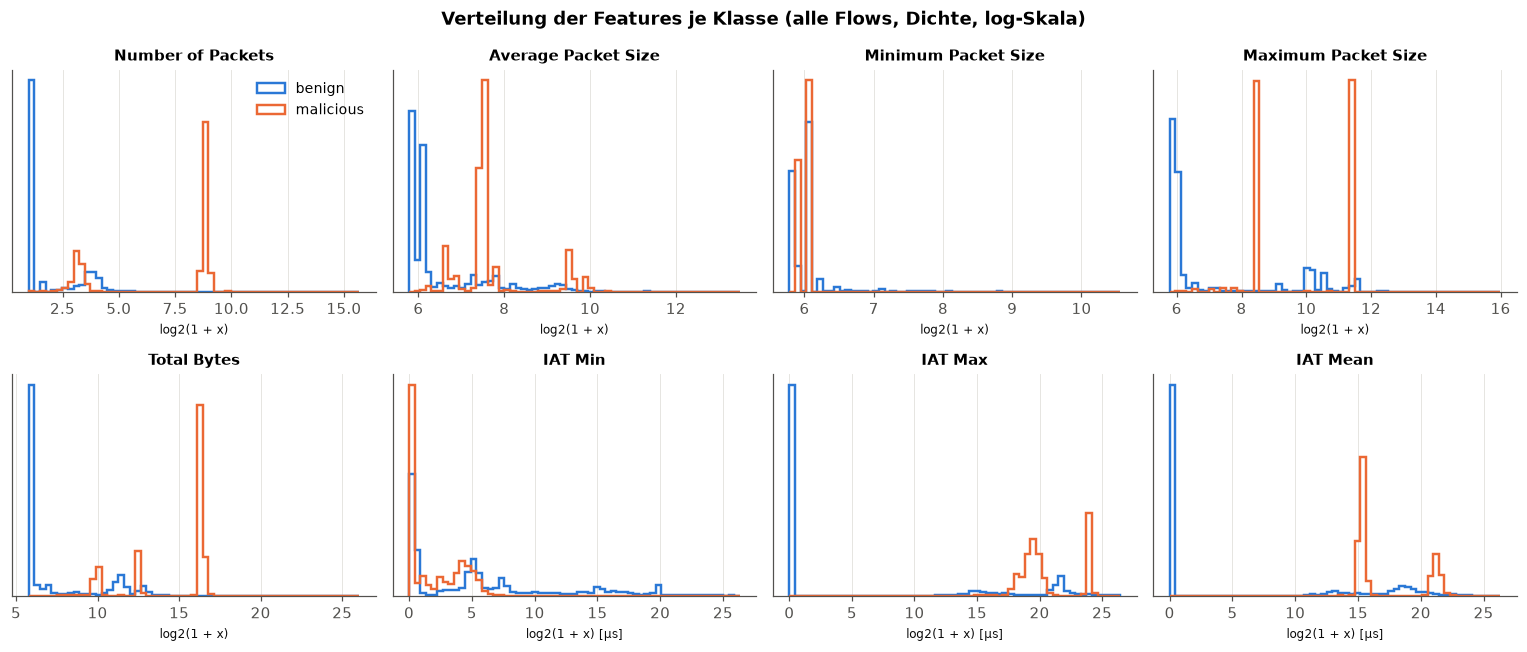

In [9]:
def class_hist(data, title, columns=LOG_SCALED_COLUMNS, bins=60):
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for ax, col in zip(axes.flat, columns):
        vals = data[col].replace(np.inf, np.nan)
        if col.startswith("IAT"):
            vals = vals * 1e6  # Mikrosekunden, wie in normalize_training_data
        logged = np.log2(1 + vals)
        edges = np.linspace(np.nanmin(logged), np.nanmax(logged), bins)
        for label, color in CLASS_COLORS.items():
            v = logged[data["Label"] == label].dropna()
            ax.hist(v, bins=edges, density=True, histtype="step", linewidth=1.6, color=color, label=label)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel("log2(1 + x)" + (" [µs]" if col.startswith("IAT") else ""), fontsize=8)
        ax.set_yticks([])
    axes.flat[0].legend(fontsize=9)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

class_hist(raw, "Verteilung der Features je Klasse (alle Flows, Dichte, log-Skala)")

Anteil der malicious Flows über Port 443 (HTTPS): 100.00%


Label,benign,malicious,All
is_svc,,,
HTTPS (Port 443),28335,78622,106957
kein HTTPS,188847,0,188847
All,217182,78622,295804


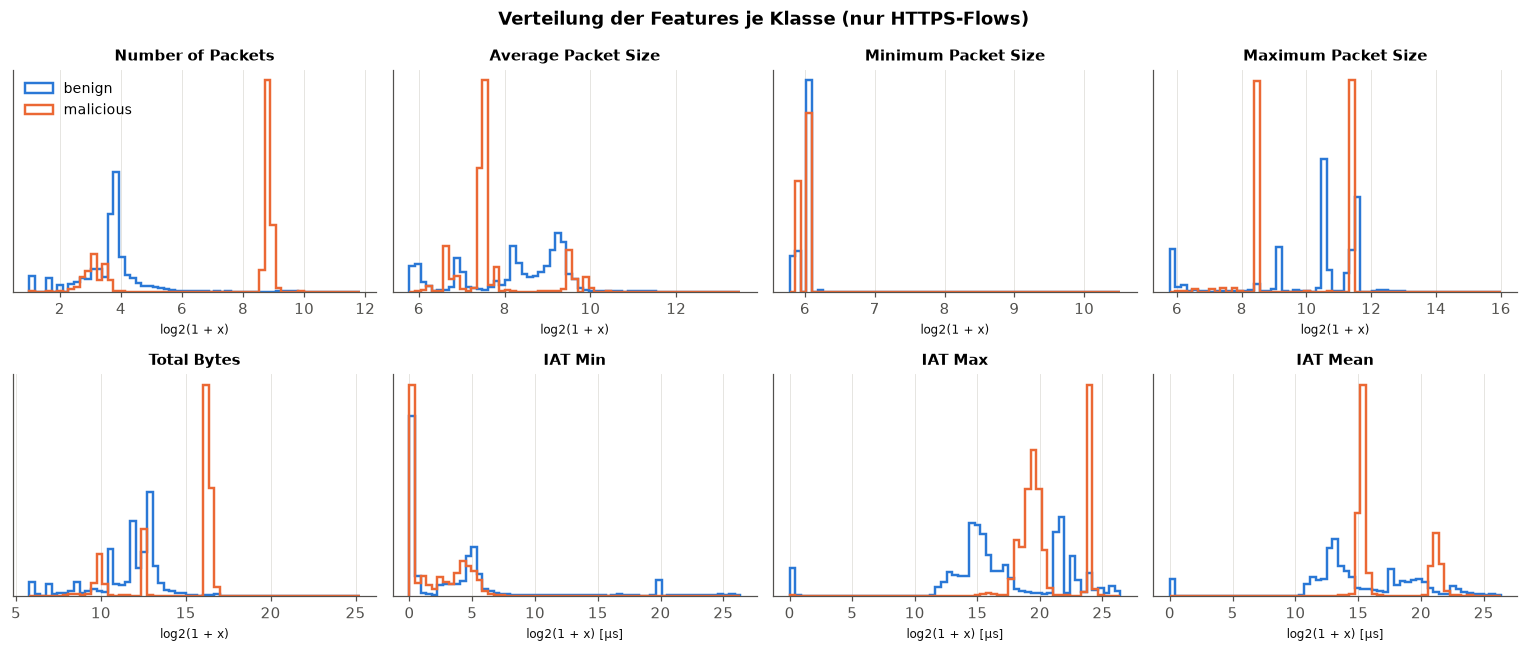

In [10]:
svc = raw[raw["is_svc"]]
print(f"Anteil der malicious Flows über Port {SVC_PORT} ({SVC}): {raw.loc[raw['is_mal'] == 1, 'is_svc'].mean():.2%}")
display(pd.crosstab(raw["is_svc"].map({True: f"{SVC} (Port {SVC_PORT})", False: f"kein {SVC}"}), raw["Label"], margins=True))
class_hist(svc, f"Verteilung der Features je Klasse (nur {SVC}-Flows)")


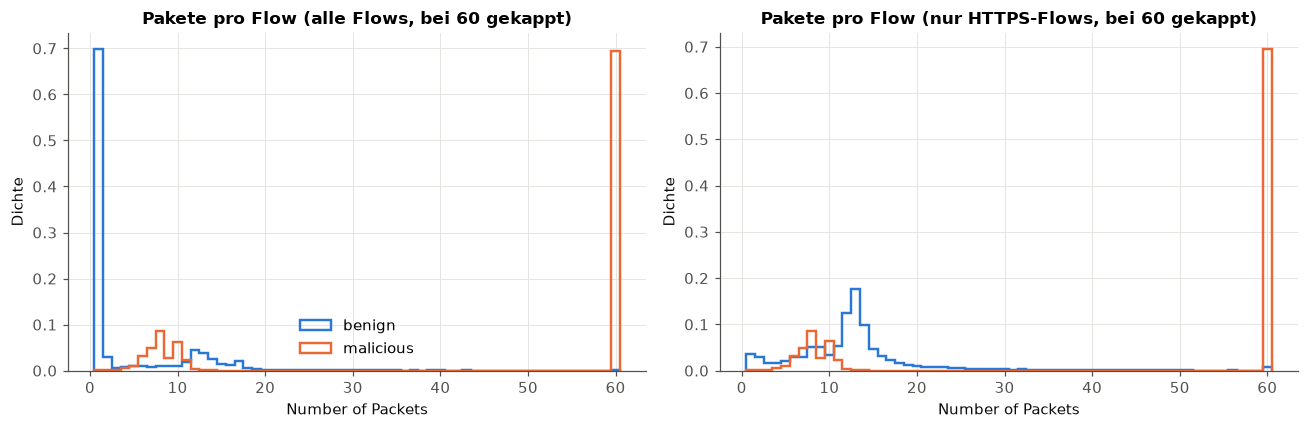

Häufigste Paketanzahlen bei malicious Flows:
{8: 0.085, 10: 0.063, 7: 0.048, 6: 0.033, 9: 0.027, 11: 0.023, 445: 0.012, 440: 0.012}


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, data) in zip(axes, [("alle Flows", raw), (f"nur {SVC}-Flows", svc)]):
    for label, color in CLASS_COLORS.items():
        v = data.loc[data["Label"] == label, "Number of Packets"].clip(upper=60)
        ax.hist(v, bins=np.arange(0.5, 61.5, 1), density=True, histtype="step", linewidth=1.6, color=color, label=label)
    ax.set_title(f"Pakete pro Flow ({title}, bei 60 gekappt)")
    ax.set_xlabel("Number of Packets")
    ax.set_ylabel("Dichte")
axes[0].legend()
plt.tight_layout()
plt.show()

print("Häufigste Paketanzahlen bei malicious Flows:")
print(raw.loc[raw["is_mal"] == 1, "Number of Packets"].value_counts(normalize=True).head(8).round(3).to_dict())

## 4. Ports & IP-Adressen

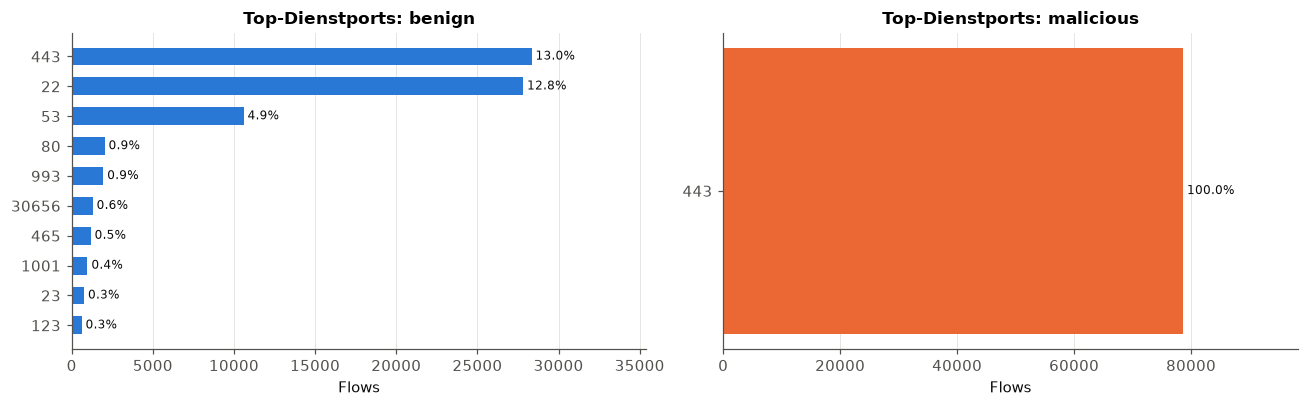

In [12]:
def top_ports(label, n=10):
    sub = raw[raw["Label"] == label]
    # "Dienst-Port" = der kleinere der beiden Ports eines Flows (Server-Seite)
    service = np.minimum(sub["Source Port"], sub["Destination Port"])
    return service.value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, label in zip(axes, ["benign", "malicious"]):
    tp = top_ports(label)
    total = (raw["Label"] == label).sum()
    ax.barh([str(p) for p in tp.index], tp.values, color=CLASS_COLORS[label], height=0.6)
    for i, v in enumerate(tp.values):
        ax.text(v, i, f" {v / total:.1%}", va="center", fontsize=8, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, tp.max() * 1.25)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Top-Dienstports: {label}")
    ax.set_xlabel("Flows")
plt.tight_layout()
plt.show()

Überwachter Server (häufigste IP): 37.60.229.253 – in 100.0% aller Flows
Flows mit Quelle == Server: 49.8%

Unterschiedliche Angreifer-IPs: 1
Unterschiedliche Gegenstellen in benignen Flows: 5,524
Angreifer-IPs, die auch benigne Flows haben: 0
Anteil der Angriffs-Flows durch die Top-10-Angreifer: 100.0%


,count,mean,std,min,25%,50%,75%,max
Flows pro Angreifer-IP,1.0000,"78,622.0000",NaN,"78,622.0000","78,622.0000","78,622.0000","78,622.0000","78,622.0000"


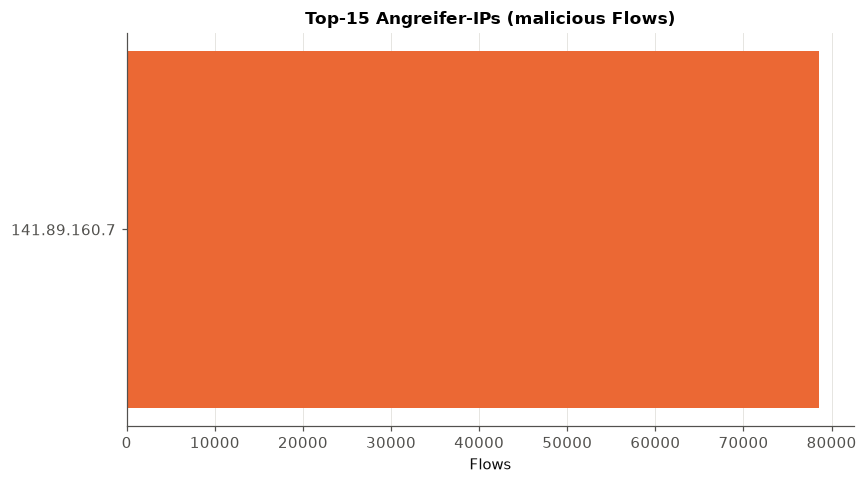

In [13]:
ip_counts = pd.concat([raw["Source IP"], raw["Destination IP"]]).value_counts()
SERVER_IP = ip_counts.index[0]
raw["peer_ip"] = np.where(raw["Source IP"] == SERVER_IP, raw["Destination IP"], raw["Source IP"])
print(f"Überwachter Server (häufigste IP): {SERVER_IP} – in {(raw['Source IP'].eq(SERVER_IP) | raw['Destination IP'].eq(SERVER_IP)).mean():.1%} aller Flows")
print(f"Flows mit Quelle == Server: {(raw['Source IP'] == SERVER_IP).mean():.1%}")

mal_peers = raw.loc[raw["is_mal"] == 1, "peer_ip"].value_counts()
ben_peers = raw.loc[raw["is_mal"] == 0, "peer_ip"]
print(f"\nUnterschiedliche Angreifer-IPs: {len(mal_peers):,}")
print(f"Unterschiedliche Gegenstellen in benignen Flows: {ben_peers.nunique():,}")
print(f"Angreifer-IPs, die auch benigne Flows haben: {len(set(mal_peers.index) & set(ben_peers)):,}")
print(f"Anteil der Angriffs-Flows durch die Top-10-Angreifer: {mal_peers.head(10).sum() / mal_peers.sum():.1%}")
display(mal_peers.describe().to_frame("Flows pro Angreifer-IP").T)

top = mal_peers.head(15)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=C_MAL, height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Top-15 Angreifer-IPs (malicious Flows)")
ax.set_xlabel("Flows")
plt.tight_layout()
plt.show()

Angreifer-IPs im Test-Teil: 1, davon im Training nie als Angreifer gesehen: 0
Malicious Test-Flows von neuen Angreifern: 0 von 20,196


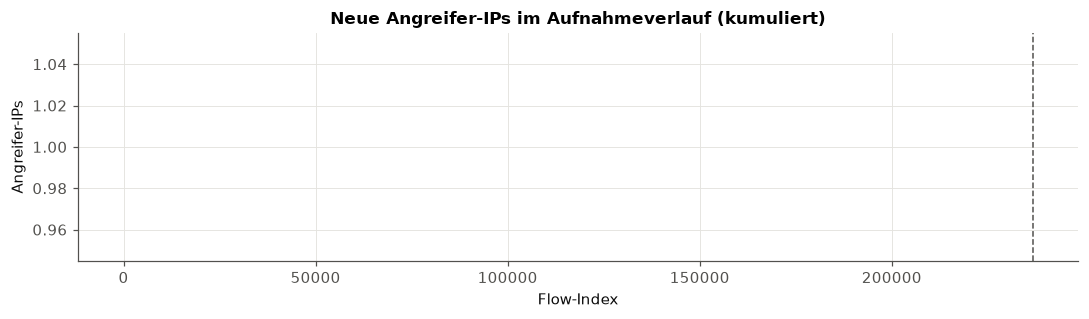

In [14]:
# Wann tauchen Angreifer zum ersten Mal auf? Relevant dafür, ob Test-Angreifer schon im Training gesehen wurden.
first_seen = raw[raw["is_mal"] == 1].groupby("peer_ip").apply(lambda g: g.index.min(), include_groups=False)
test_mal = raw.loc[split_idx:][raw.loc[split_idx:, "is_mal"] == 1]
unseen_attackers = set(first_seen[first_seen >= split_idx].index)
print(f"Angreifer-IPs im Test-Teil: {test_mal['peer_ip'].nunique():,}, davon im Training nie als Angreifer gesehen: {len(unseen_attackers):,}")
print(f"Malicious Test-Flows von neuen Angreifern: {test_mal['peer_ip'].isin(unseen_attackers).sum():,} von {len(test_mal):,}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.sort(first_seen.values), np.arange(1, len(first_seen) + 1), color=C_MAL)
ax.axvline(split_idx, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set_title("Neue Angreifer-IPs im Aufnahmeverlauf (kumuliert)")
ax.set_xlabel("Flow-Index")
ax.set_ylabel("Angreifer-IPs")
plt.tight_layout()
plt.show()

## 5. Korrelationen & normalisierte Features

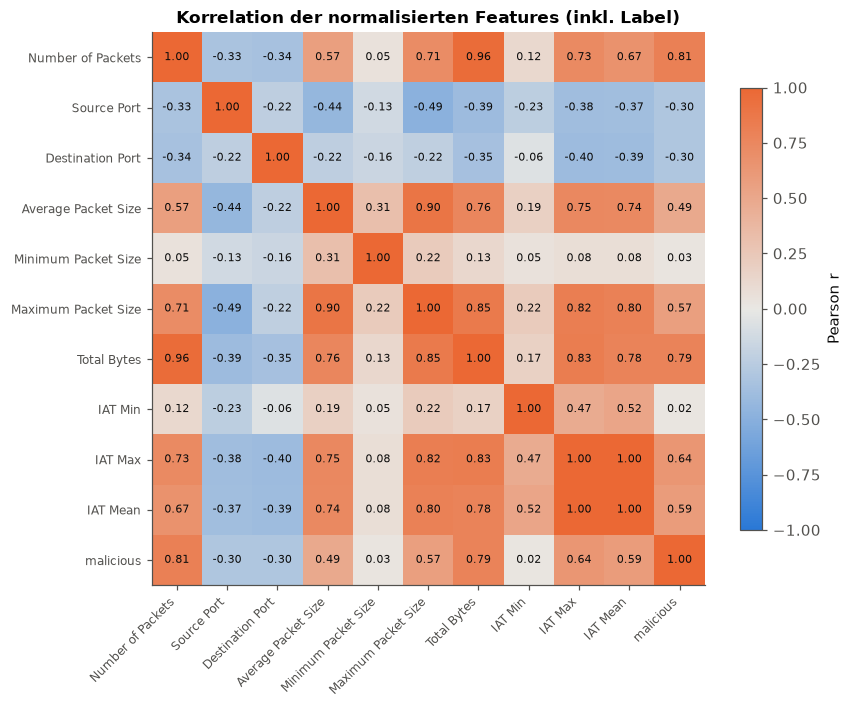

,r mit Label
Number of Packets,0.8089
Total Bytes,0.7866
IAT Max,0.6375
IAT Mean,0.5913
Maximum Packet Size,0.5701
Average Packet Size,0.4881
Source Port,-0.3015
Destination Port,-0.2993
Minimum Packet Size,0.0281
IAT Min,0.0220


In [15]:
norm = normalize_training_data(raw)
corr = norm[FEATURE_COLUMNS].assign(malicious=raw["is_mal"]).corr()

diverging = LinearSegmentedColormap.from_list("div", [C_BENIGN, "#e9e8e4", C_MAL])
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Korrelation der normalisierten Features (inkl. Label)")
plt.tight_layout()
plt.show()

corr["malicious"].drop("malicious").sort_values(key=abs, ascending=False).to_frame("r mit Label")

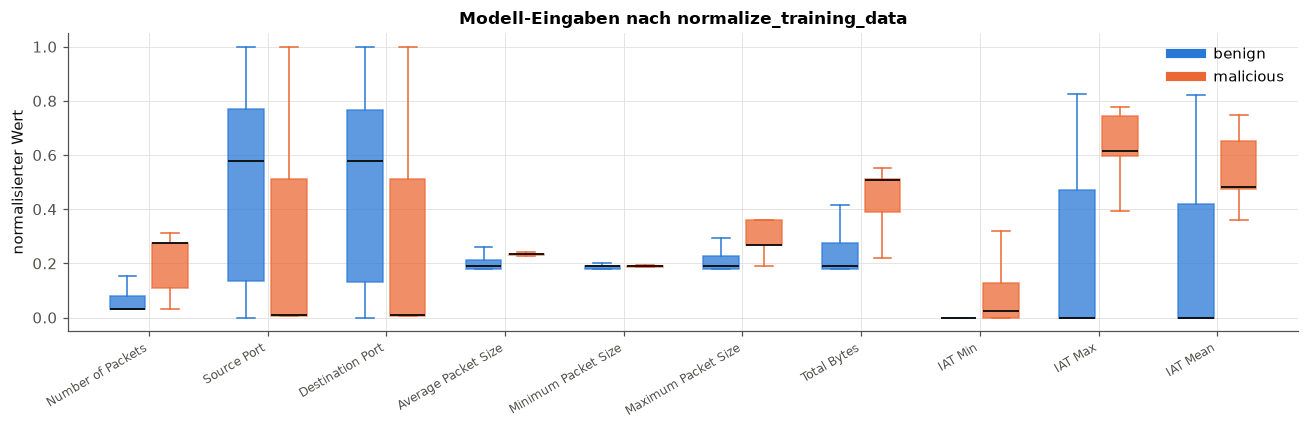

,min,max,mean,std
Number of Packets,0.0312,0.4903,0.0991,0.0913
Source Port,0.0000,1.0000,0.4282,0.3403
Destination Port,0.0000,1.0000,0.4271,0.3404
Average Packet Size,0.1807,0.4216,0.2126,0.0345
Minimum Packet Size,0.1807,0.3299,0.1876,0.0078
Maximum Packet Size,0.1807,0.4998,0.2439,0.0695
Total Bytes,0.1807,0.8143,0.2938,0.1274
IAT Min,0.0000,0.8231,0.0576,0.1245
IAT Max,0.0000,0.8261,0.3050,0.3194
IAT Mean,0.0000,0.8231,0.2613,0.2756


In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
positions = np.arange(len(FEATURE_COLUMNS))
for offset, (label, color) in zip([-0.18, 0.18], CLASS_COLORS.items()):
    data = [norm.loc[norm["Label"] == label, c].values for c in FEATURE_COLUMNS]
    bp = ax.boxplot(data, positions=positions + offset, widths=0.3, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, linewidth=1.2), whiskerprops=dict(color=color),
                    capprops=dict(color=color), boxprops=dict(facecolor=color, edgecolor=color, alpha=0.75))
    ax.plot([], [], color=color, linewidth=6, label=label)
ax.set_xticks(positions, FEATURE_COLUMNS, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("normalisierter Wert")
ax.set_title("Modell-Eingaben nach normalize_training_data")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

norm[FEATURE_COLUMNS].describe().T[["min", "max", "mean", "std"]]

## 6. Modelltraining


In [17]:
x = torch.tensor(norm[FEATURE_COLUMNS].to_numpy(), dtype=torch.float32)
y = torch.tensor(raw["is_mal"].to_numpy(), dtype=torch.float32)
X_train, X_test = x[:split_idx], x[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
test_df = raw.iloc[split_idx:].reset_index(drop=True)
print(f"Train: {len(y_train):,} Flows ({int(y_train.sum()):,} malicious) | Test: {len(y_test):,} Flows ({int(y_test.sum()):,} malicious)")

torch.manual_seed(SEED)
model = AttackDetectionNet()
print(model)
print(f"Parameter: {sum(p.numel() for p in model.parameters()):,}")

Train: 236,643 Flows (58,426 malicious) | Test: 59,161 Flows (20,196 malicious)
AttackDetectionNet(
  (layers): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)
Parameter: 593


In [18]:
%%time
model.fit(list(zip(X_train, y_train)), epochs=EPOCHS, batch_size=BATCH_SIZE)

Training on cpu.


Epoch 1/20 completed. average loss: 0.1103331010333375


Epoch 2/20 completed. average loss: 0.0600831952076224


Epoch 3/20 completed. average loss: 0.055296783977176335


Epoch 4/20 completed. average loss: 0.049971760131804405


...

Epoch 17/20 completed. average loss: 0.018784487634652267


Epoch 18/20 completed. average loss: 0.018836061282922523


Epoch 19/20 completed. average loss: 0.018589864433872758


Epoch 20/20 completed. average loss: 0.018255212826217143
Training finished.


CPU times: user 5min 10s, sys: 2.25 s, total: 5min 12s
Wall time: 5min 27s


## 7. Evaluation auf dem Test-Split

In [19]:
def predict_scores(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(X).squeeze(1)).numpy()


def roc_pr(y_true, scores):
    order = np.argsort(-scores, kind="mergesort")
    s, t = scores[order], y_true[order]
    distinct = np.r_[np.where(np.diff(s))[0], len(s) - 1]
    tp = np.cumsum(t)[distinct]
    fp = (distinct + 1) - tp
    P, N = t.sum(), len(t) - t.sum()
    tpr = np.r_[0, tp / P]
    fpr = np.r_[0, fp / N]
    precision = np.r_[1, tp / (tp + fp)]
    roc_auc = np.trapezoid(tpr, fpr)
    ap = np.sum(np.diff(tpr) * precision[1:])  # Average Precision
    return fpr, tpr, precision, roc_auc, ap


def metrics(y_true, y_pred, scores=None):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum()); fn = int(((y_true == 1) & (y_pred == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    out = {
        "Flows": len(y_true), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Accuracy": (tp + tn) / len(y_true), "Precision": prec, "Recall": rec, "Specificity": spec,
        "F1": 2 * prec * rec / (prec + rec) if prec and rec else np.nan,
        "Balanced Acc.": (rec + spec) / 2, "MCC": (tp * tn - fp * fn) / denom if denom else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
    }
    if scores is not None and 0 < y_true.sum() < len(y_true):
        _, _, _, auc, ap = roc_pr(y_true, scores)
        out["ROC-AUC"], out["PR-AUC (AP)"] = auc, ap
    return out


INT_COLS = ["Flows", "TP", "FP", "TN", "FN"]

def show(res):
    return pd.DataFrame(res).T.astype({c: int for c in INT_COLS})


y_true = y_test.int().numpy()
scores = predict_scores(model, X_test)
y_pred = (scores >= CUTOFF).astype(int)

# Ausgabe im Format von model.main()
print_metrics("All flows", torch.tensor(y_true), torch.tensor(y_pred))

-> All flows (59161 samples)
TP: 20044 (33.88 %), FP: 122 (0.21 %), TN: 38843 (65.66 %), FN: 152 (0.26 %)
Precision: 99.40 %
Recall: 99.25 %
F1 Score: 99.32 %


In [20]:
results = {"Modell – alle Test-Flows": metrics(y_true, y_pred, scores)}
show(results)

,Flows,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced Acc.,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,59161,20044,122,38843,152,0.9954,0.9940,0.9925,0.9969,0.9932,0.9947,0.9897,0.0031,0.9997,0.9991


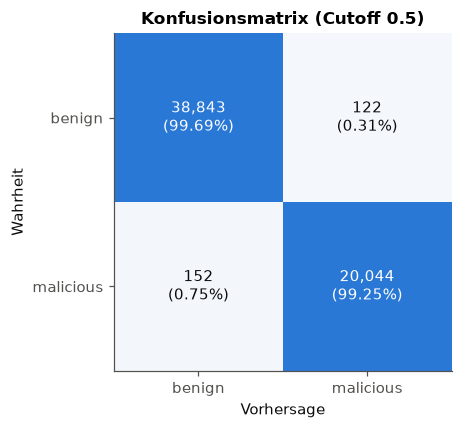

In [21]:
blues = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", C_BENIGN])


def plot_confusion(m, title):
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(4.8, 4))
    ax.imshow(cm_norm, cmap=blues, vmin=0, vmax=1)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]:.2%})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.6 else INK, fontsize=10)
    ax.set_xticks([0, 1], ["benign", "malicious"])
    ax.set_yticks([0, 1], ["benign", "malicious"])
    ax.set_xlabel("Vorhersage")
    ax.set_ylabel("Wahrheit")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


plot_confusion(results["Modell – alle Test-Flows"], f"Konfusionsmatrix (Cutoff {CUTOFF})")


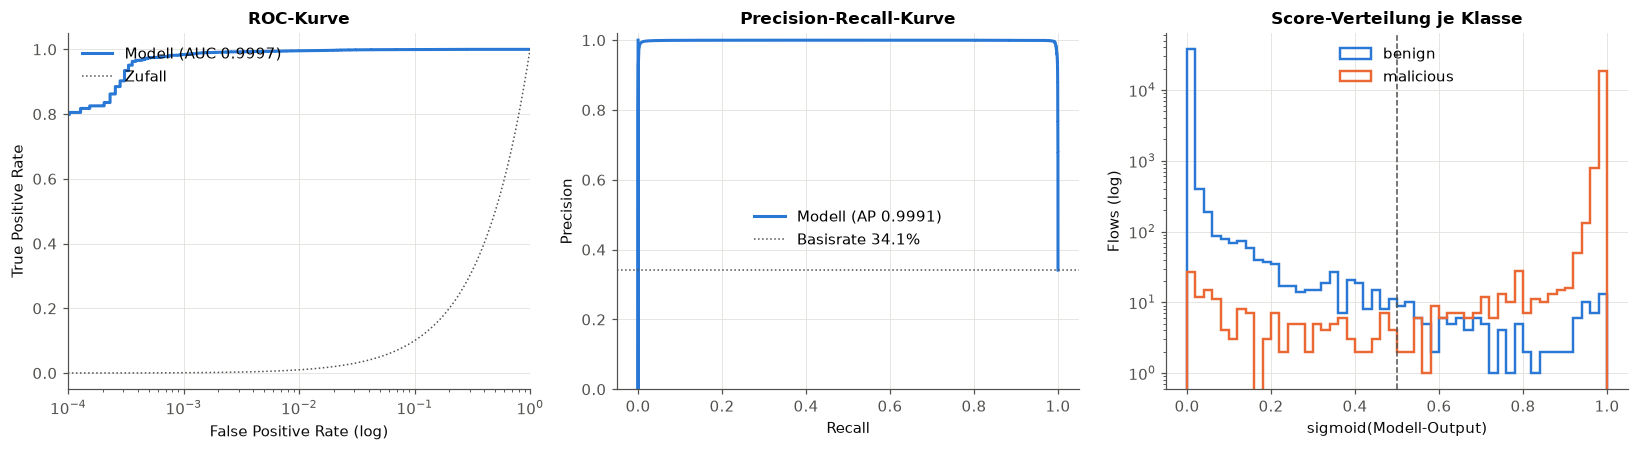

In [22]:
fpr, tpr, precision, auc, ap = roc_pr(y_true, scores)
base_rate = y_true.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(fpr, tpr, color=C_BENIGN, label=f"Modell (AUC {auc:.4f})")
diag = np.logspace(-5, 0, 200)
axes[0].plot(diag, diag, color=INK_MUTED, linestyle=":", linewidth=1, label="Zufall")
axes[0].set_xscale("log")
axes[0].set_xlim(1e-4, 1)
axes[0].set_xlabel("False Positive Rate (log)")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC-Kurve")
axes[0].legend(loc="upper left")

axes[1].plot(tpr, precision, color=C_BENIGN, label=f"Modell (AP {ap:.4f})")
axes[1].axhline(base_rate, color=INK_MUTED, linestyle=":", linewidth=1, label=f"Basisrate {base_rate:.1%}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Precision-Recall-Kurve")
axes[1].legend(loc="center", bbox_to_anchor=(0.5, 0.45))

edges = np.linspace(0, 1, 51)
for label, color, cls in [("benign", C_BENIGN, 0), ("malicious", C_MAL, 1)]:
    axes[2].hist(scores[y_true == cls], bins=edges, color=color, histtype="step", linewidth=1.6, label=label)
axes[2].axvline(CUTOFF, color=INK_MUTED, linestyle="--", linewidth=1)
axes[2].set_yscale("log")
axes[2].set_xlabel("sigmoid(Modell-Output)")
axes[2].set_ylabel("Flows (log)")
axes[2].set_title("Score-Verteilung je Klasse")
axes[2].legend(loc="upper center")
plt.tight_layout()
plt.show()

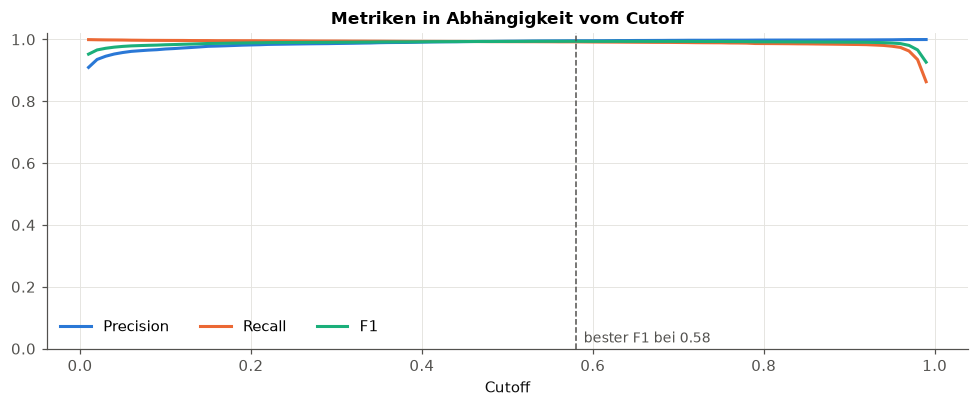

,TP,FP,FN,Precision,Recall,F1,FPR
Cutoff,,,,,,,
0.1000,20127,648,69,0.9688,0.9966,0.9825,0.0166
0.3000,20085,272,111,0.9866,0.9945,0.9906,0.0070
0.5000,20044,122,152,0.9940,0.9925,0.9932,0.0031
0.7000,19991,63,205,0.9969,0.9898,0.9933,0.0016
0.9000,19866,38,330,0.9981,0.9837,0.9908,0.0010
0.5800,20033,92,163,0.9954,0.9919,0.9937,0.0024


In [23]:
thresholds = np.round(np.linspace(0.01, 0.99, 99), 2)
sweep = pd.DataFrame([{"Cutoff": t, **metrics(y_true, (scores >= t).astype(int))} for t in thresholds]).set_index("Cutoff")

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, color in [("Precision", C_BENIGN), ("Recall", C_MAL), ("F1", C_ALT)]:
    ax.plot(sweep.index, sweep[col], color=color, label=col)
best = sweep["F1"].idxmax()
ax.axvline(best, color=INK_MUTED, linestyle="--", linewidth=1)
ax.text(best, 0.02, f"  bester F1 bei {best:.2f}", color=INK_MUTED, fontsize=9)
ax.set_xlabel("Cutoff")
ax.set_ylim(0, 1.02)
ax.set_title("Metriken in Abhängigkeit vom Cutoff")
ax.legend(loc="lower left", ncol=3)
plt.tight_layout()
plt.show()

sweep.loc[[0.1, 0.3, CUTOFF, 0.7, 0.9, round(best, 2)], ["TP", "FP", "FN", "Precision", "Recall", "F1", "FPR"]].drop_duplicates()

## 8. Robustheit


In [24]:
svc_mask = test_df["is_svc"].to_numpy()
results[f"Modell – nur {SVC}-Flows"] = metrics(y_true[svc_mask], y_pred[svc_mask], scores[svc_mask])
results[f"Baseline Port {SVC_PORT} – alle Flows"] = metrics(y_true, svc_mask.astype(int))

show(results)


,Flows,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced Acc.,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,59161,20044,122,38843,152,0.9954,0.9940,0.9925,0.9969,0.9932,0.9947,0.9897,0.0031,0.9997,0.9991
Modell – nur HTTPS-Flows,25251,20044,31,5024,152,0.9928,0.9985,0.9925,0.9939,0.9955,0.9932,0.9777,0.0061,0.9993,0.9998
Baseline Port 443 – alle Flows,59161,20196,5055,33910,0,0.9146,0.7998,1.0000,0.8703,0.8888,0.9351,0.8343,0.1297,NaN,NaN


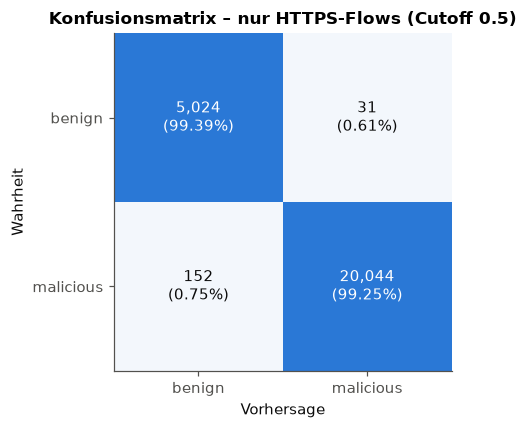

In [25]:
plot_confusion(results[f"Modell – nur {SVC}-Flows"], f"Konfusionsmatrix – nur {SVC}-Flows (Cutoff {CUTOFF})")


In [26]:
new_att = test_df["peer_ip"].isin(unseen_attackers).to_numpy()
by_group = []
for name, mask in [("neue Angreifer-IPs", new_att), ("bekannte Angreifer-IPs", ~new_att)]:
    sel = (y_true == 1) & mask
    by_group.append({"Gruppe": name, "IPs": test_df.loc[sel, "peer_ip"].nunique(), "malicious Flows": int(sel.sum()),
                     "erkannt": int(y_pred[sel].sum()), "Recall": y_pred[sel].mean() if sel.any() else np.nan,
                     "Median-Score": np.median(scores[sel]) if sel.any() else np.nan})
pd.DataFrame(by_group).set_index("Gruppe")

,IPs,malicious Flows,erkannt,Recall,Median-Score
Gruppe,,,,,
neue Angreifer-IPs,0,0,0,NaN,NaN
bekannte Angreifer-IPs,1,20196,20044,0.9925,1.0000


In [27]:
%%time
PORT_IDX = [FEATURE_COLUMNS.index("Source Port"), FEATURE_COLUMNS.index("Destination Port")]
x_np = x.clone()
x_np[:, PORT_IDX] = 0
X_train_np, X_test_np = x_np[:split_idx], x_np[split_idx:]

torch.manual_seed(SEED)
model_noport = AttackDetectionNet()
model_noport.fit(list(zip(X_train_np, y_train)), epochs=EPOCHS, batch_size=BATCH_SIZE)

Training on cpu.


Epoch 1/20 completed. average loss: 0.11869635406588865


Epoch 2/20 completed. average loss: 0.07651754146947522


Epoch 3/20 completed. average loss: 0.07085079014412238


Epoch 4/20 completed. average loss: 0.0683212571378481


...

Epoch 17/20 completed. average loss: 0.020378147730465958


Epoch 18/20 completed. average loss: 0.020074287365090804


Epoch 19/20 completed. average loss: 0.019961689963599673


Epoch 20/20 completed. average loss: 0.019375638555271017
Training finished.


CPU times: user 5min 1s, sys: 1.64 s, total: 5min 3s
Wall time: 5min 19s


In [28]:
scores_np = predict_scores(model_noport, X_test_np)
y_pred_np = (scores_np >= CUTOFF).astype(int)
results["Ablation ohne Ports – alle Flows"] = metrics(y_true, y_pred_np, scores_np)
results[f"Ablation ohne Ports – nur {SVC}-Flows"] = metrics(y_true[svc_mask], y_pred_np[svc_mask], scores_np[svc_mask])

summary = show(results)
summary[["Flows", "TP", "FP", "FN", "Precision", "Recall", "F1", "MCC", "FPR", "ROC-AUC", "PR-AUC (AP)"]]

,Flows,TP,FP,FN,Precision,Recall,F1,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,59161,20044,122,152,0.9940,0.9925,0.9932,0.9897,0.0031,0.9997,0.9991
Modell – nur HTTPS-Flows,25251,20044,31,152,0.9985,0.9925,0.9955,0.9777,0.0061,0.9993,0.9998
Baseline Port 443 – alle Flows,59161,20196,5055,0,0.7998,1.0000,0.8888,0.8343,0.1297,NaN,NaN
Ablation ohne Ports – alle Flows,59161,19950,68,246,0.9966,0.9878,0.9922,0.9882,0.0017,0.9995,0.9992
Ablation ohne Ports – nur HTTPS-Flows,25251,19950,22,246,0.9989,0.9878,0.9933,0.9678,0.0044,0.9990,0.9997


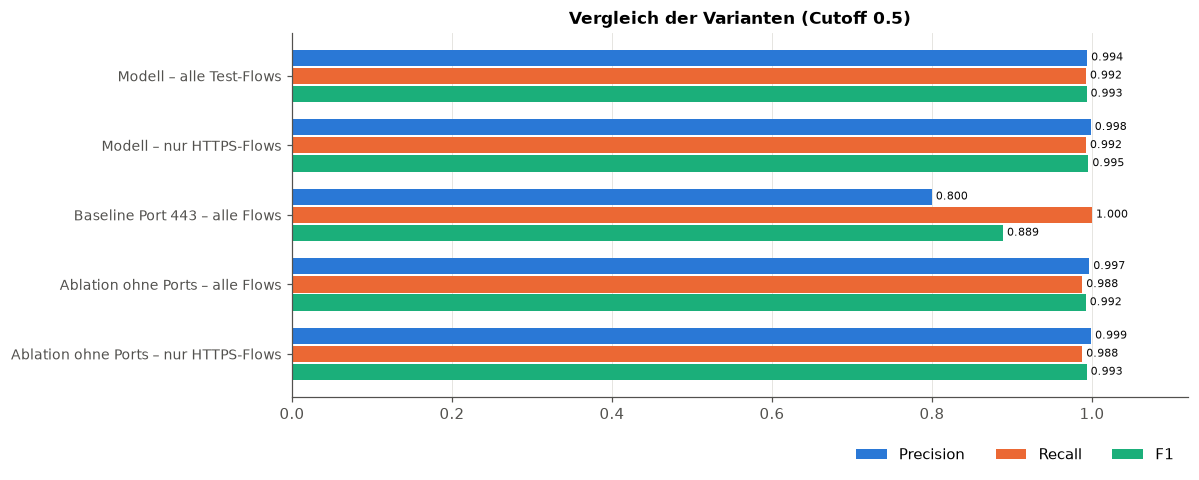

In [29]:
plot_rows = ["Modell – alle Test-Flows", f"Modell – nur {SVC}-Flows", f"Baseline Port {SVC_PORT} – alle Flows",
             "Ablation ohne Ports – alle Flows", f"Ablation ohne Ports – nur {SVC}-Flows"]
plot_metrics = [("Precision", C_BENIGN), ("Recall", C_MAL), ("F1", C_ALT)]
fig, ax = plt.subplots(figsize=(11, 4.5))
ypos = np.arange(len(plot_rows))
h = 0.26
for k, (metric, color) in enumerate(plot_metrics):
    vals = summary.loc[plot_rows, metric].astype(float).values
    ax.barh(ypos + (k - 1) * h, vals, height=h * 0.9, color=color, label=metric)
    for yy, v in zip(ypos + (k - 1) * h, vals):
        ax.text(v, yy, f" {v:.3f}", va="center", fontsize=7, color=INK)
ax.set_yticks(ypos, plot_rows, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.grid(axis="y", visible=False)
ax.set_title(f"Vergleich der Varianten (Cutoff {CUTOFF})")
ax.legend(loc="lower right", ncol=3, bbox_to_anchor=(1, -0.22))
plt.tight_layout()
plt.show()

## 9. Feature Importance


In [30]:
N_REPEATS = 10


def permutation_importance(m, X, y_true, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed)
    base_f1 = metrics(y_true, (predict_scores(m, X) >= CUTOFF).astype(int))["F1"]
    rows = []
    for j, col in enumerate(FEATURE_COLUMNS):
        d_f1 = []
        for _ in range(n_repeats):
            Xp = X.clone()
            Xp[:, j] = Xp[torch.from_numpy(rng.permutation(len(Xp))), j]
            s = predict_scores(m, Xp)
            d_f1.append(base_f1 - metrics(y_true, (s >= CUTOFF).astype(int))["F1"])
        rows.append({"Feature": col, "Δ F1": np.mean(d_f1), "Δ F1 std": np.std(d_f1)})
    return pd.DataFrame(rows).set_index("Feature")


svc_t = torch.tensor(svc_mask)
importance = {
    "Modell – alle Test-Flows": permutation_importance(model, X_test, y_true),
    f"Modell – nur {SVC}-Flows": permutation_importance(model, X_test[svc_t], y_true[svc_mask]),
    f"Ablation ohne Ports – nur {SVC}-Flows": permutation_importance(model_noport, X_test_np[svc_t], y_true[svc_mask]),
}
pd.concat({k: v["Δ F1"] for k, v in importance.items()}, axis=1).sort_values(
    "Modell – alle Test-Flows", ascending=False)

,Modell – alle Test-Flows,Modell – nur HTTPS-Flows,Ablation ohne Ports – nur HTTPS-Flows
Feature,,,
IAT Max,0.6103,0.1604,0.1926
Total Bytes,0.3847,0.2127,0.0943
Number of Packets,0.2837,0.3179,0.3326
IAT Mean,0.1669,0.1807,0.0198
IAT Min,0.0907,0.0424,0.0059
Average Packet Size,0.0529,0.0284,0.0057
Maximum Packet Size,0.0168,0.0344,0.0029
Source Port,0.0055,0.0046,0.0000
Destination Port,0.0014,0.0009,0.0000


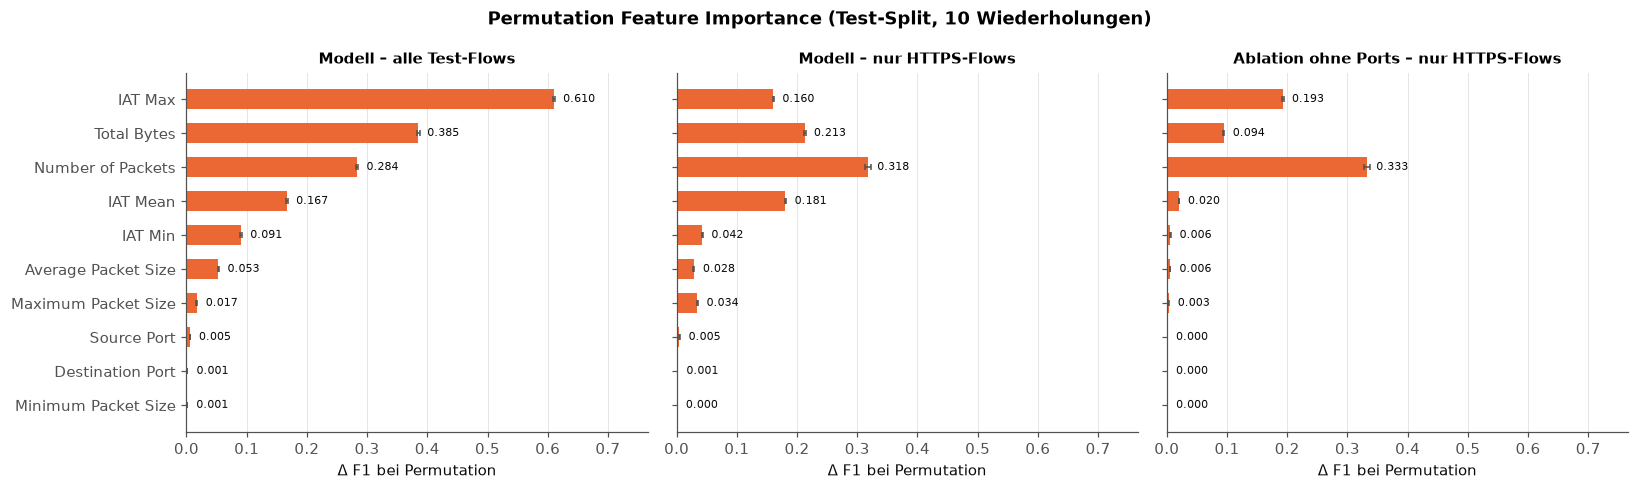

In [31]:
order = importance["Modell – alle Test-Flows"]["Δ F1"].sort_values().index  # wichtigstes Feature oben
panels = list(importance.items())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
lim = max(imp["Δ F1"].max() + imp["Δ F1 std"].max() for _, imp in panels) * 1.25
for ax, (title, imp) in zip(axes, panels):
    imp = imp.loc[order]
    ax.barh(imp.index, imp["Δ F1"].clip(lower=0), xerr=imp["Δ F1 std"], color=C_MAL, height=0.6,
            error_kw=dict(ecolor=INK_MUTED, elinewidth=1, capsize=2))
    for yy, v in enumerate(imp["Δ F1"]):
        ax.text(max(v, 0) + lim * 0.02, yy, f"{v:.3f}", va="center", fontsize=7, color=INK)
    ax.set_xlim(0, lim)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Δ F1 bei Permutation")
    ax.set_title(title, fontsize=10)
fig.suptitle(f"Permutation Feature Importance (Test-Split, {N_REPEATS} Wiederholungen)", fontweight="bold")
plt.tight_layout()
plt.show()

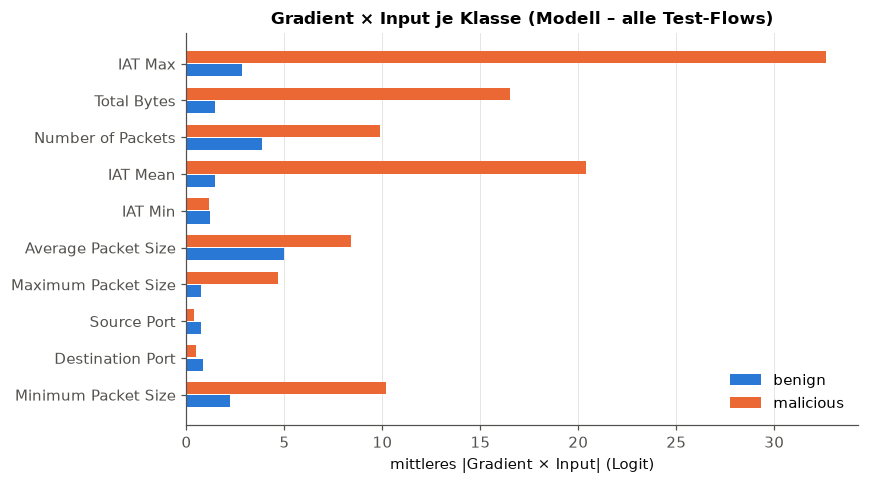

In [32]:
Xg = X_test.clone().requires_grad_(True)
model(Xg).sum().backward()
attr = (Xg.grad * X_test).abs().numpy()
gxi = pd.DataFrame({label: attr[y_true == cls].mean(axis=0) for label, cls in [("benign", 0), ("malicious", 1)]},
                   index=FEATURE_COLUMNS).loc[order]

fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(gxi))
for k, (label, color) in enumerate(CLASS_COLORS.items()):
    ax.barh(ypos + (k - 0.5) * 0.36, gxi[label], height=0.33, color=color, label=label)
ax.set_yticks(ypos, gxi.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mittleres |Gradient × Input| (Logit)")
ax.set_title("Gradient × Input je Klasse (Modell – alle Test-Flows)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Fehleranalyse

In [33]:
err = test_df.assign(score=scores, pred=y_pred)
err["Fall"] = np.select(
    [(err.is_mal == 1) & (err.pred == 1), (err.is_mal == 0) & (err.pred == 1),
     (err.is_mal == 1) & (err.pred == 0), (err.is_mal == 0) & (err.pred == 0)],
    ["TP", "FP", "FN", "TN"], default="?")
cols = ["Number of Packets", "Average Packet Size", "Total Bytes", "IAT Mean"]
display(err.groupby("Fall")[cols + ["score"]].median().assign(Flows=err["Fall"].value_counts()))

print("False Positives nach Dienstport:")
fp_ports = np.minimum(err.loc[err.Fall == "FP", "Source Port"], err.loc[err.Fall == "FP", "Destination Port"]).value_counts().head(10)
print(fp_ports.to_dict())
print("\nFalse Negatives – Paketanzahl:")
print(err.loc[err.Fall == "FN", "Number of Packets"].value_counts().head(10).to_dict())
print("\nFalse Negatives – Top-Angreifer-IPs:")
print(err.loc[err.Fall == "FN", "peer_ip"].value_counts().head(10).to_dict())

,Number of Packets,Average Packet Size,Total Bytes,IAT Mean,score,Flows
Fall,,,,,,
FN,4.0000,74.0000,252.0000,0.5167,0.1265,152
FP,5.0000,146.3482,819.5000,1.5548,0.7026,122
TN,1.0000,66.0000,66.0000,0.0000,0.0001,38843
TP,433.0000,185.8823,"78,831.5000",0.0438,1.0000,20044


False Positives nach Dienstport:
{80: 38, 443: 31, 22: 21, 993: 11, 465: 8, 25: 7, 32741: 2, 587: 1, 6443: 1, 5141: 1}

False Negatives – Paketanzahl:
{3: 33, 6: 26, 4: 26, 2: 20, 7: 10, 1: 9, 25: 3, 10: 2, 8: 2, 23: 2}

False Negatives – Top-Angreifer-IPs:
{'141.89.160.7': 152}


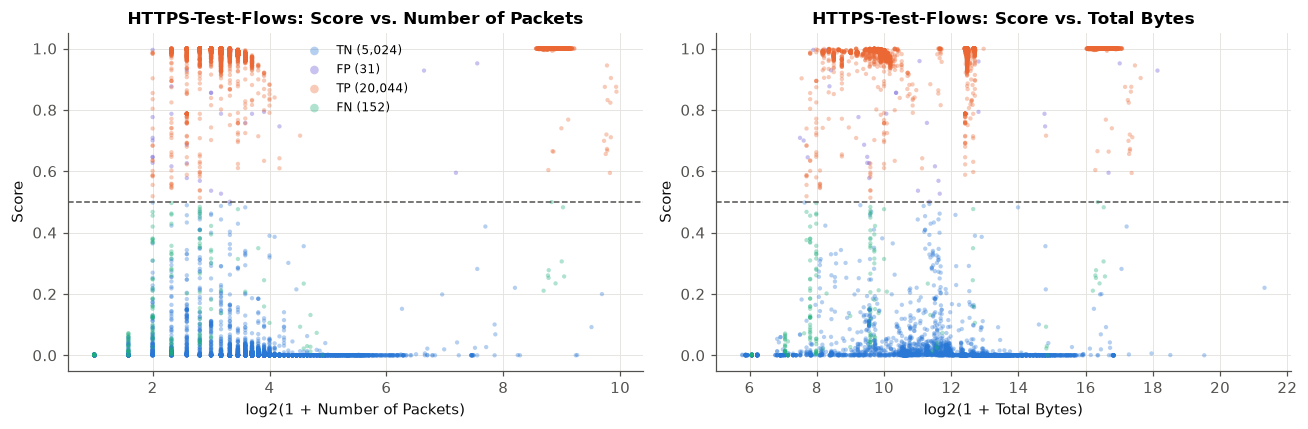

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
svc_err = err[err["is_svc"]]
for ax, col in zip(axes, ["Number of Packets", "Total Bytes"]):
    for case, color in [("TN", C_BENIGN), ("FP", "#6250d6"), ("TP", C_MAL), ("FN", C_ALT)]:
        v = svc_err.loc[svc_err["Fall"] == case, col]
        if len(v):
            ax.scatter(np.log2(1 + v), svc_err.loc[v.index, "score"], s=8, alpha=0.35, color=color, label=f"{case} ({len(v):,})", edgecolors="none")
    ax.set_xlabel(f"log2(1 + {col})")
    ax.set_ylabel("Score")
    ax.axhline(CUTOFF, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(f"{SVC}-Test-Flows: Score vs. {col}")
axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()